# Live robot -> GR00T actions

Connect to the running Station daemon and policy server, capture one observation, request one action chunk, then execute its first 16 actions while displaying the live camera feed. Each requested joint target is clipped to `MAX_DELTA_TICKS` from its current position and kept within its calibrated range.

## 1. Import required libraries

In [19]:
import logging

import numpy as np
from IPython.display import display
from PIL import Image

from inference_client.frame import StationFrame
from inference_client.policy_client import PolicyClient

## 2. Connect to the live robot

Set the local paths and endpoints below. Install this package in the active kernel (`uv pip install -e .` from the repository root); `NORMA_CORE_PATH` must point to the norma-core checkout containing Station's Python modules and generated protobufs.

In [20]:
NORMA_CORE_PATH = "/home/del/robot-pizza-cup/elrobot/norma-core"
STATION_SERVER = "localhost"
POLICY_HOST, POLICY_PORT = "81.85.2.138", 5556
API_TOKEN = None  # Set only if the policy server requires authentication.
TASK = "move the tcp in circles"
IMAGE_KEYS = ("cam0", "cam1")  # Match policy modality config.
IMAGE_INDICES = (1, 2)  # Select the first and third Station cameras, skipping the middle one.
STATE_KEY = "state"
BUS_SERIAL = "5B3D050348"  # Read from the Station web viewer.
MOTOR_IDS = [1, 2, 3, 4, 5, 6, 7, 8]  # Must match joint order.
TIMEOUT = 5.0
MAX_DELTA_TICKS = 100  # Clip each target to this maximum per-joint position change.

from inference_client.station_live import StationLink, add_norma_core_to_path, unnormalize_goal

add_norma_core_to_path(NORMA_CORE_PATH)
logger = logging.getLogger("live_robot_notebook")
logging.basicConfig(level=logging.INFO)

link = await StationLink.connect(STATION_SERVER, logger)
policy = PolicyClient(
    host=POLICY_HOST,
    port=POLICY_PORT,
    timeout_ms=int(TIMEOUT * 1000),
    api_token=API_TOKEN,
)
assert policy.ping(), f"Can't reach policy server at {POLICY_HOST}:{POLICY_PORT}"
modality_config = policy.get_modality_config()
print("Policy modality config:", modality_config)

INFO:live_robot_notebook:Connection established
INFO:live_robot_notebook:Initial setup successful


Policy modality config: {'video': {'delta_indices': [0], 'modality_keys': ['cam0', 'cam1'], 'sin_cos_embedding_keys': None, 'mean_std_embedding_keys': None, 'action_configs': None}, 'state': {'delta_indices': [0], 'modality_keys': ['state'], 'sin_cos_embedding_keys': None, 'mean_std_embedding_keys': None, 'action_configs': None}, 'action': {'delta_indices': [0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15], 'modality_keys': ['action'], 'sin_cos_embedding_keys': None, 'mean_std_embedding_keys': None, 'action_configs': [{'rep': 'ABSOLUTE', 'type': 'NON_EEF', 'format': 'DEFAULT', 'state_key': None}]}, 'language': {'delta_indices': [0], 'modality_keys': ['task'], 'sin_cos_embedding_keys': None, 'mean_std_embedding_keys': None, 'action_configs': None}}


## Preview all cameras

Station publishes three cameras while this embodiment and policy use two. Run this to inspect every feed in `Frame.images` order. The notebook maps `cam0` to `images[0]` and `cam1` to `images[2]`, deliberately skipping the middle camera. Change `IMAGE_INDICES` only if the desired camera order differs.

INFO:live_robot_notebook:Read stream 1 started


3 cameras in Frame.images
images[0] -> NOT USED by the policy


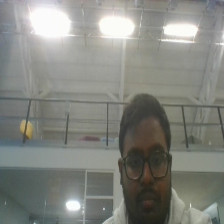

images[1] -> cam0


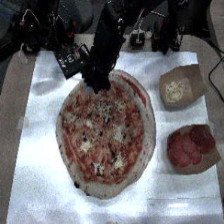

images[2] -> cam1


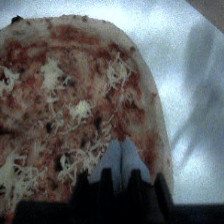

In [21]:
reader, _ = await link.fetch_fresh_frame(b"", timeout=TIMEOUT)
preview = StationFrame.from_live(reader, task=TASK)
print(f"{len(preview.images)} cameras in Frame.images")
for i, img in enumerate(preview.images):
    used = IMAGE_KEYS[IMAGE_INDICES.index(i)] if i in IMAGE_INDICES else "NOT USED by the policy"
    print(f"images[{i}] -> {used}")
    display(Image.fromarray(img.decode()))

In [22]:
#for i in range(10):
#    reader, _ = await link.fetch_fresh_frame(b"", timeout=TIMEOUT)
#    frame = StationFrame.from_live(reader, task=TASK)
#    print(f"Frame {i}: {len(frame.images)} cameras in Frame.images")
#    for j, img in enumerate(frame.images):
#        used = IMAGE_KEYS[IMAGE_INDICES.index(j)] if j in IMAGE_INDICES else "NOT USED by the policy"
#        print(f"images[{j}] -> {used}")
#        display(Image.fromarray(img.decode()))

## 3. Helper functions

Run these code cells from top to bottom to define the helpers, then run the final cell to capture one observation, request one action chunk, and execute it.

In [23]:
def tcp_path_stays_above_ground(
    joint_path,
    fk_tcp_global,
    ground_z,
    clearance=0.0,
    samples_per_segment=20,
):
    """Return (safe, minimum sampled TCP Z) for a joint path.

    `joint_path` includes the starting configuration. `fk_tcp_global` maps a
    joint configuration to TCP XYZ in global coordinates. Joint and distance
    units must be consistent. This sampled check is approximate, not continuous.
    """
    path = np.asarray(joint_path, dtype=float)
    if path.ndim != 2 or len(path) == 0:
        raise ValueError("joint_path must have shape (steps, joints) and include the start")
    if samples_per_segment < 1 or clearance < 0:
        raise ValueError("samples_per_segment must be positive; clearance non-negative")

    configurations = [path[0]]
    for start, end in zip(path[:-1], path[1:]):
        configurations.extend(
            start + fraction * (end - start)
            for fraction in np.linspace(0.0, 1.0, samples_per_segment + 1)[1:]
        )

    z_values = []
    for configuration in configurations:
        tcp_xyz = np.asarray(fk_tcp_global(configuration), dtype=float)
        if tcp_xyz.shape != (3,):
            raise ValueError("fk_tcp_global must return global XYZ")
        z_values.append(float(tcp_xyz[2]))

    minimum_z = min(z_values)
    return minimum_z >= ground_z + clearance, minimum_z

In [24]:
NUM_FUTURE_ACTIONS = 16


def request_action_chunk(observation, joint_count):
    action, info = policy.get_action(observation)
    if not action:
        raise ValueError("Policy returned no action arrays")

    action_values = np.asarray(next(iter(action.values())))
    if action_values.ndim != 3 or action_values.shape[0] != 1:
        raise ValueError(f"Expected action shape (1, chunk, joints), got {action_values.shape}")
    if action_values.shape[1] < NUM_FUTURE_ACTIONS:
        raise ValueError(f"Policy returned {action_values.shape[1]} actions; need {NUM_FUTURE_ACTIONS}")
    if action_values.shape[2] != joint_count:
        raise ValueError(f"Policy predicted {action_values.shape[2]} joints; live frame has {joint_count}")

    return action_values[0, :NUM_FUTURE_ACTIONS, :], info

In [25]:
def bounded_motor_goals(goal_norm, frame):
    if len(goal_norm) != len(frame.joints):
        raise ValueError(f"Action has {len(goal_norm)} joints; live frame has {len(frame.joints)}")

    goals = []
    clipped_count = 0
    for value, joint in zip(goal_norm, frame.joints):
        if not joint.range_min <= joint.position <= joint.range_max:
            raise ValueError(f"Current position {joint.position} is outside the calibrated range")

        requested = unnormalize_goal(value, joint.range_min, joint.range_max)
        lower = max(joint.range_min, joint.position - MAX_DELTA_TICKS)
        upper = min(joint.range_max, joint.position + MAX_DELTA_TICKS)
        bounded = max(lower, min(requested, upper))
        goals.append(bounded)
        clipped_count += requested != bounded

    return goals, clipped_count

In [26]:
IMAGE_INDICES

(1, 2)

In [27]:
async def execute_action_chunk(actions, frame_id, joint_count):
    if MAX_DELTA_TICKS <= 0:
        raise ValueError("MAX_DELTA_TICKS must be positive")
    if len(MOTOR_IDS) != joint_count:
        raise ValueError(f"Configured {len(MOTOR_IDS)} motor IDs for {joint_count} joints")

    reader, frame_id = await link.fetch_fresh_frame(frame_id, timeout=TIMEOUT)
    frame = StationFrame.from_live(reader, task=TASK)
    if not frame.images:
        raise ValueError("Station frame contains no camera images")
    #camera_view = display(Image.fromarray(frame.images[0].decode()), display_id=True)
    actions = actions[:8]
    for index, goal_norm in enumerate(actions):
        goals, clipped_count = bounded_motor_goals(goal_norm, frame)
        if clipped_count:
            print(f"action {index + 1}/{len(actions)}: clipped {clipped_count} joint targets")

        command = link.build_sync_write_command(BUS_SERIAL, MOTOR_IDS, goals)
        await link.send(command)

        reader, frame_id = await link.fetch_fresh_frame(frame_id, timeout=TIMEOUT)
        frame = StationFrame.from_live(reader, task=TASK)
        if not frame.images:
            raise ValueError("Station frame contains no camera images")
        #camera_view.update(Image.fromarray(frame.images[0].decode()))
        print(f"executed action {index + 1}/{len(actions)}")
    else:
        print(f"completed all {len(actions)} actions")

In [28]:
async def run_live_policy_chunk():
    reader, frame_id = await link.fetch_fresh_frame(b"", timeout=TIMEOUT)
    frame = StationFrame.from_live(reader, task=TASK)
    observation = frame.to_observation(IMAGE_KEYS, STATE_KEY, image_indices=IMAGE_INDICES)
    #print(f"captured {len(frame.joints)} joints and {len(frame.images)} images")

    actions, info = request_action_chunk(observation, len(frame.joints))
    #print("policy info:", info)
    #print(f"received {len(actions)} actions; executing them now")
    await execute_action_chunk(actions, frame_id, len(frame.joints))

In [29]:
# reader, frame_id = await link.fetch_fresh_frame(b"", timeout=TIMEOUT)
# frame = StationFrame.from_live(reader, task=TASK)
# observation = frame.to_observation(IMAGE_KEYS, STATE_KEY, image_indices=IMAGE_INDICES)

In [30]:
# display cam0 and cam1 in observation

# display(Image.fromarray(observation["video"]["cam0"][0, 0]))
# display(Image.fromarray(observation["video"]["cam1"][0, 0]))


In [31]:
for i in range(30):
    await run_live_policy_chunk()

INFO:live_robot_notebook:Read stream 2 started
INFO:live_robot_notebook:Read stream 3 started
INFO:live_robot_notebook:Read stream 4 started
INFO:live_robot_notebook:Read stream 5 started
INFO:live_robot_notebook:Read stream 6 started


executed action 1/8
action 2/8: clipped 1 joint targets
executed action 2/8


INFO:live_robot_notebook:Read stream 7 started
INFO:live_robot_notebook:Read stream 8 started
INFO:live_robot_notebook:Read stream 9 started


executed action 3/8
executed action 4/8


INFO:live_robot_notebook:Read stream 10 started
INFO:live_robot_notebook:Read stream 11 started
INFO:live_robot_notebook:Read stream 12 started


...

executed action 2/8
executed action 3/8
executed action 4/8


INFO:live_robot_notebook:Read stream 371 started
INFO:live_robot_notebook:Read stream 372 started
INFO:live_robot_notebook:Read stream 373 started


executed action 5/8
executed action 6/8


INFO:live_robot_notebook:Read stream 374 started
INFO:live_robot_notebook:Read stream 375 started


executed action 7/8
executed action 8/8
completed all 8 actions


## Close the policy client

Run when finished. Restart the kernel before reconnecting if you need to recreate the Station connection.

In [56]:
policy.close()